# Experiment analysis

The results come from `just experiments tune` / `just experiments compare` (files in `results/`).
This notebook only reads them and calls functions from `analysis.py` - the computations and figures live there.
Figures are saved as PDF to `figures/`.

In [1]:
import sys
from pathlib import Path

# The kernel starts in research/experiments - make `app` and `research` importable.
BACKEND = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "app").is_dir())
if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))

%load_ext autoreload
%autoreload 2

import json

import pandas as pd

from research.experiments import analysis as A

A.thesis_style()
pd.set_option("display.precision", 2)
pd.set_option("display.max_rows", 100)

## 1. Tuning (TUNE scenarios)

In every scenario each variant is ranked among the variants of its own family
(1 - the best mean score), then the ranks are averaged over the scenarios.

In [2]:
tune_runs, tune_curves, tune_meta = A.load("tune")
print(tune_meta.get("config"), tune_meta.get("budget"), tune_meta.get("seeds"), "seeds")
tuning = A.tuning_table(tune_runs)
tuning.groupby("family").head(5)

per-muscle-v3 30000 10 seeds


,family,variant,mean_rank,mean_pct
0,ga,pop=120 mut=0.6 cx=session,1.88,30.67
1,ga,pop=60 mut=0.6 cx=session,2.25,30.51
2,ga,pop=30 mut=0.6 cx=session,2.50,30.35
3,ga,pop=30 mut=0.9 cx=session,4.12,29.36
4,ga,pop=60 mut=0.3 cx=session,5.50,29.30
18,hill,patience=1000,2.00,30.98
19,hill,patience=2000,2.25,30.79
20,hill,patience=500,2.25,30.59
21,hill,patience=200,3.50,29.76
22,memetic,ls=2x25,3.00,30.47


In [3]:
best = A.best_variants(tune_runs)
best

,family,variant,mean_rank,mean_pct
0,ga,pop=120 mut=0.6 cx=session,1.88,30.67
1,hill,patience=1000,2.00,30.98
2,memetic,ls=2x25,3.00,30.47


In [ ]:
fig = A.ga_heatmap(tuning)
A.save(fig, "ga_tuning")

In [ ]:
tuning[tuning["family"].isin(["hill", "memetic"])]

Put the selected variants into `COMPARISON` in `algorithms.py`
and run `just experiments compare`.

## 2. Comparison (TEST scenarios)

In [4]:
runs, curves, meta = A.load("compare")
table = A.summary(runs)
table.pivot(index="family", columns="scenario", values="mean").loc[
    [f for f in A.FAMILY_ORDER if f in set(runs["family"])]
]

scenario,fbw-3x45-home,ppl-3x45-gym,ppl-6x60-gym,ul-4x60-gym
family,,,,
random,-27.64,-9.26,64.42,36.03
greedy,-36.98,-13.26,85.79,51.74
hill,-5.00,18.49,92.81,74.93
ga,-5.56,18.38,92.50,75.13
memetic,-5.63,17.79,92.58,75.12


WindowsPath('C:/Projects/loxofit/backend/research/experiments/figures/porownanie_boxplot.pdf')

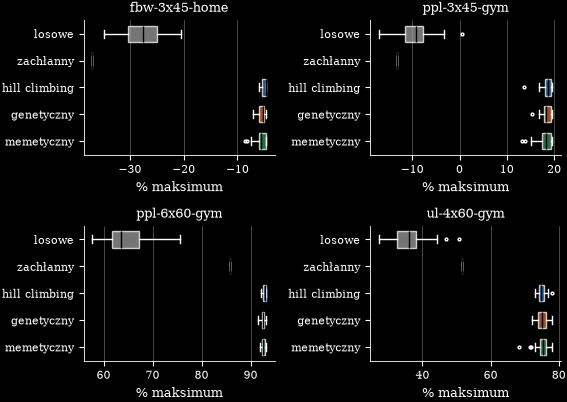

In [5]:
fig = A.boxplots(runs)
A.save(fig, "porownanie_boxplot")

WindowsPath('C:/Projects/loxofit/backend/research/experiments/figures/porownanie_boxplot_metody.pdf')

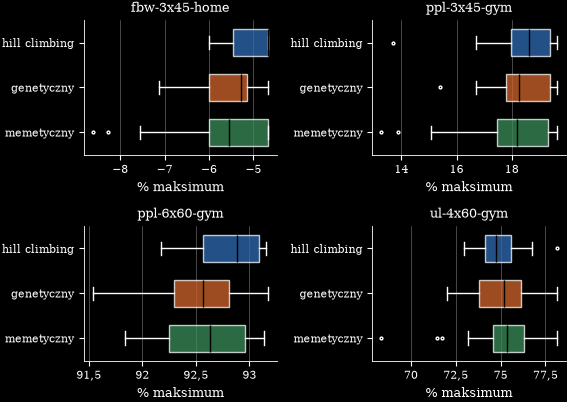

In [6]:
fig = A.boxplots(runs, families=A.SEARCH)
A.save(fig, "porownanie_boxplot_metody")

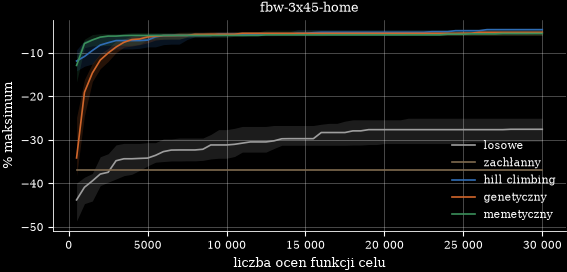

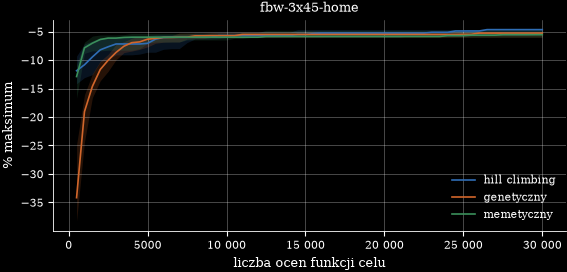

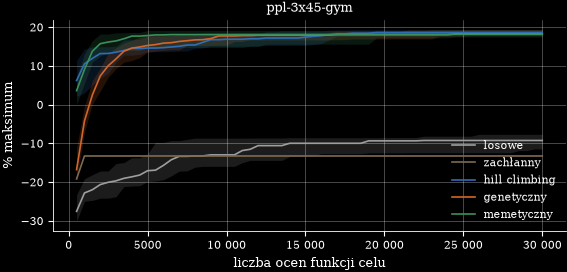

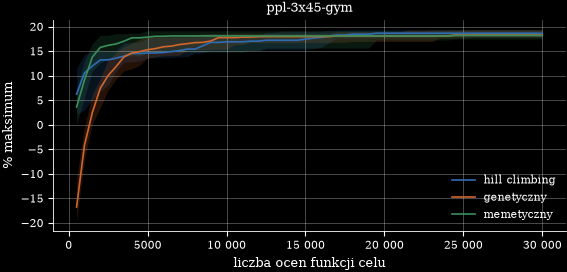

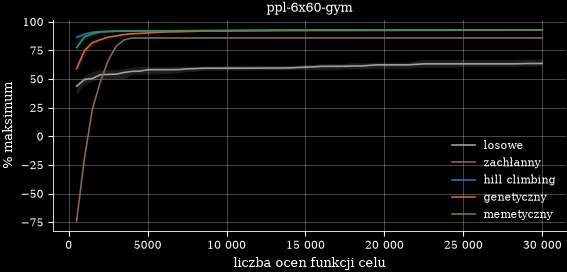

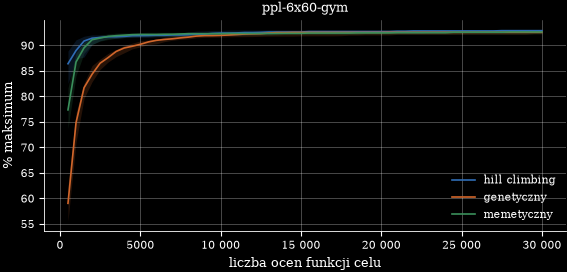

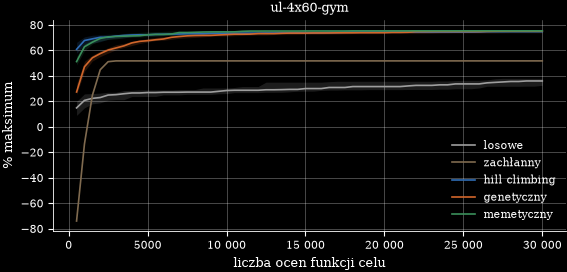

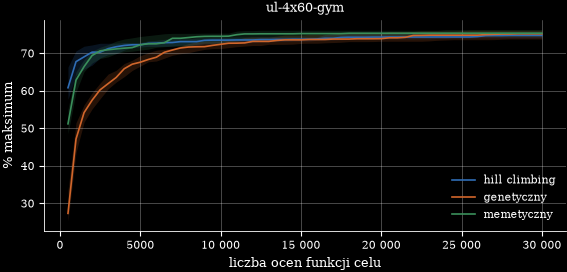

In [7]:
for scenario in sorted(runs["scenario"].unique()):
    fig = A.convergence(runs, curves, scenario)
    A.save(fig, f"zbieznosc_{scenario}")
    fig = A.convergence(runs, curves, scenario, families=A.SEARCH)
    A.save(fig, f"zbieznosc_{scenario}_metody")

### Statistical tests

Mean ranks and the Friedman test over the scenarios, then every pair of algorithms
within each scenario: the Mann-Whitney U test with Holm's correction and the A12 effect size.

In [ ]:
statistic, p = A.friedman(runs)
print(f"Friedman: statystyka {statistic:.2f}, p = {p:.4f}")
A.mean_ranks(runs)

In [ ]:
pairs = A.pairwise(runs)
search = ["hill", "ga", "memetic"]
pairs[pairs["a"].isin(search) & pairs["b"].isin(search)]

### Tables

In [ ]:
latex = table.assign(algorytm=table["family"].map(A.LABELS))[
    ["scenario", "algorytm", "mean", "sd", "median", "best", "overtime_min"]
]
print(A.latex_table(latex, caption="Wyniki algorytmów (\\% maksimum)", label="tab:porownanie"))

### Example plans

In [ ]:
plans = json.loads((A.RESULTS_DIR / "compare" / "plans.json").read_text(encoding="utf-8"))
for key, value in plans.items():
    if key.startswith("ul-4x60-gym"):
        print(key, round(value["score"], 2))
        for session in value["plan"]:
            print("   ", session["focus"], session["exercises"])